# **GPU check**

In [32]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("GPU Test:")
with tf.device('/GPU:0'):
    a = tf.random.normal([1000, 1000])
    b = tf.random.normal([1000, 1000])
    c = tf.matmul(a, b)

print("GPU computation successful!")

TensorFlow: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU Test:
GPU computation successful!


# **Dataset upload**

# **Extract the ZIP file.**

In [1]:
from google.colab import files
import os

print("Select your FER2013 dataset ZIP file")
uploaded = files.upload()

zip_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError(
        "ZIP file upload pannunga. "
        "Dataset ZIP select pannunga."
    )

print("\nUploaded ZIP files:")
for name in zip_files:
    print(name, "-", round(os.path.getsize(name) / (1024**2), 2), "MB")

Select your FER2013 dataset ZIP file


Saving emotions_dataset.zip to emotions_dataset.zip

Uploaded ZIP files:
emotions_dataset.zip - 60.32 MB


In [2]:
import zipfile
import os

zip_path = "/content/emotions_dataset.zip"
extract_path = "/content/emotions_dataset"
with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall(extract_path)
print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['train', 'test']


## **Check the dataset structure.**

In [4]:
import os

for root, dirs, files in os.walk("/content/emotions_dataset"):
    if files:
        print(root, "->", len(files), "files")

/content/emotions_dataset/train/happy -> 7215 files
/content/emotions_dataset/train/fear -> 4097 files
/content/emotions_dataset/train/sad -> 4830 files
/content/emotions_dataset/train/surprise -> 3171 files
/content/emotions_dataset/train/neutral -> 4965 files
/content/emotions_dataset/train/angry -> 3995 files
/content/emotions_dataset/train/disgust -> 436 files
/content/emotions_dataset/test/happy -> 1774 files
/content/emotions_dataset/test/fear -> 1024 files
/content/emotions_dataset/test/sad -> 1247 files
/content/emotions_dataset/test/surprise -> 831 files
/content/emotions_dataset/test/neutral -> 1233 files
/content/emotions_dataset/test/angry -> 958 files
/content/emotions_dataset/test/disgust -> 111 files


# **Check the total number of images.**

In [5]:
import os

dataset_path = "/content/emotions_dataset"
image_extensions = (".jpg", ".jpeg", ".png")

total_images = 0

for root, dirs, files in os.walk(dataset_path):
    count = sum(
        1 for file in files
        if file.lower().endswith(image_extensions)
    )
    total_images += count

print("Total images:", total_images)

Total images: 35887


# **Setup Paths**

In [6]:
import os

# Your actual paths after extraction
TRAIN_DIR = '/content/emotions_dataset/train'
TEST_DIR = '/content/emotions_dataset/test'

# Output dirs (in Colab)
BASE_OUT = '/content/emosonic_output'
MODELS_DIR = os.path.join(BASE_OUT, 'models')
PLOTS_DIR = os.path.join(BASE_OUT, 'plots')
PRED_DIR = os.path.join(BASE_OUT, 'predictions')

for d in [MODELS_DIR, PLOTS_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)

print("Paths set:")
print(f"  Train: {TRAIN_DIR}")
print(f"  Test:  {TEST_DIR}")
print(f"  Models: {MODELS_DIR}")

# Quick check — folder names
print("\n Train folders:", sorted(os.listdir(TRAIN_DIR)))
print("Test folders: ", sorted(os.listdir(TEST_DIR)))


Paths set:
  Train: /content/emotions_dataset/train
  Test:  /content/emotions_dataset/test
  Models: /content/emosonic_output/models

 Train folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Test folders:  ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


# **Imports The libraries**

In [7]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import Model,load_model
from tensorflow.keras.layers import (Input, Conv2D, BatchNormalization, MaxPooling2D, Dropout, Flatten, Dense)
from tensorflow.keras.optimizers import  Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint)
from sklearn.metrics import confusion_matrix, classification_report

print("Imports done")
print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")


Imports done
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# **Load FER2013 Data**

In [8]:
TRAIN_DIR = "/content/emotions_dataset/train"
TEST_DIR = "/content/emotions_dataset/test"
MODELS_DIR = "/content/emosonic_output/models"

import os

os.makedirs(MODELS_DIR, exist_ok=True)

print("Train path:", TRAIN_DIR)
print("Test path:", TEST_DIR)
print("Models path:", MODELS_DIR)

Train path: /content/emotions_dataset/train
Test path: /content/emotions_dataset/test
Models path: /content/emosonic_output/models


In [9]:

import os

print("Folders inside /content:")
print(os.listdir("/content"))

for root, dirs, files in os.walk("/content"):
    if "train" in dirs and "test" in dirs:
        print("\n✅ Dataset found!")
        print("TRAIN_DIR =", os.path.join(root, "train"))
        print("TEST_DIR  =", os.path.join(root, "test"))


Folders inside /content:
['.config', 'emosonic_output', 'emotions_dataset', 'emotions_dataset.zip', 'sample_data']

✅ Dataset found!
TRAIN_DIR = /content/emotions_dataset/train
TEST_DIR  = /content/emotions_dataset/test


In [10]:

import os
import cv2
import numpy as np

IMG_SHAPE = 48
BATCH_SIZE = 64
NUM_CLASSES = 7

EMOTION_LABELS = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Neutral",
    5: "Sad",
    6: "Surprise"
}

# Step 1: Find the correct train and test folders
TRAIN_DIR = None
TEST_DIR = None

for root, dirs, files in os.walk("/content"):
    if "train" in dirs and "test" in dirs:
        train_path = os.path.join(root, "train")
        test_path = os.path.join(root, "test")

        # Confirm that both folders contain emotion subfolders
        train_folders = [
            d for d in os.listdir(train_path)
            if os.path.isdir(os.path.join(train_path, d))
        ]
        test_folders = [
            d for d in os.listdir(test_path)
            if os.path.isdir(os.path.join(test_path, d))
        ]

        if len(train_folders) >= 7 and len(test_folders) >= 7:
            TRAIN_DIR = train_path
            TEST_DIR = test_path
            break

# Step 2: Check paths
if TRAIN_DIR is None or TEST_DIR is None:
    print("Train/Test folders not found!")
    print("Please check whether your ZIP file is uploaded and extracted.")
    print("\nFolders available inside /content:")
    print(os.listdir("/content"))
else:
    print("Train path:", TRAIN_DIR)
    print("Test path:", TEST_DIR)

    # Step 3: Load images using fixed emotion label order
    def load_fer2013_from_folders(train_dir, test_dir):
        X_train, y_train = [], []
        X_test, y_test = [], []

        emotion_order = [
            "angry", "disgust", "fear", "happy",
            "neutral", "sad", "surprise"
        ]

        for emotion in emotion_order:
            folder = os.path.join(train_dir, emotion)

            if not os.path.isdir(folder):
                raise FileNotFoundError(
                    f"Missing emotion folder: {folder}"
                )

            label_idx = emotion_order.index(emotion)

            for img_file in os.listdir(folder):
                img_path = os.path.join(folder, img_file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                if img is None:
                    continue

                img = cv2.resize(img, (IMG_SHAPE, IMG_SHAPE))
                X_train.append(img)
                y_train.append(label_idx)

        for emotion in emotion_order:
            folder = os.path.join(test_dir, emotion)

            if not os.path.isdir(folder):
                raise FileNotFoundError(
                    f"Missing emotion folder: {folder}"
                )

            label_idx = emotion_order.index(emotion)

            for img_file in os.listdir(folder):
                img_path = os.path.join(folder, img_file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                if img is None:
                    continue

                img = cv2.resize(img, (IMG_SHAPE, IMG_SHAPE))
                X_test.append(img)
                y_test.append(label_idx)

        return (
            np.array(X_train),
            np.array(y_train),
            np.array(X_test),
            np.array(y_test)
        )

    # Step 4: Load dataset
    print("\nLoading data...")

    X_train, y_train, X_test, y_test = load_fer2013_from_folders(
        TRAIN_DIR, TEST_DIR
    )

    print("✅ X_train:", X_train.shape)
    print("✅ y_train:", y_train.shape)
    print("✅ X_test: ", X_test.shape)
    print("✅ y_test: ", y_test.shape)

    print("\nTrain class distribution:")
    for i in range(NUM_CLASSES):
        print(f"{EMOTION_LABELS[i]:10s}: {np.sum(y_train == i)}")

    print("\n Test class distribution:")
    for i in range(NUM_CLASSES):
        print(f"{EMOTION_LABELS[i]:10s}: {np.sum(y_test == i)}")

    # Step 5: Normalize images
    X_train = X_train.astype("float32") / 255.0
    X_test = X_test.astype("float32") / 255.0

    # Add channel dimension for CNN
    X_train = X_train[..., np.newaxis]
    X_test = X_test[..., np.newaxis]

    print("\n Dataset loaded successfully!")
    print("Final X_train shape:", X_train.shape)
    print("Final X_test shape: ", X_test.shape)


Train path: /content/emotions_dataset/train
Test path: /content/emotions_dataset/test

Loading data...
✅ X_train: (28709, 48, 48)
✅ y_train: (28709,)
✅ X_test:  (7178, 48, 48)
✅ y_test:  (7178,)

Train class distribution:
Angry     : 3995
Disgust   : 436
Fear      : 4097
Happy     : 7215
Neutral   : 4965
Sad       : 4830
Surprise  : 3171

 Test class distribution:
Angry     : 958
Disgust   : 111
Fear      : 1024
Happy     : 1774
Neutral   : 1233
Sad       : 1247
Surprise  : 831

 Dataset loaded successfully!
Final X_train shape: (28709, 48, 48, 1)
Final X_test shape:  (7178, 48, 48, 1)


# **Preprocess Data**

In [11]:
# Reshape + normalize
X_train = X_train.reshape(-1, IMG_SHAPE, IMG_SHAPE, 1).astype('float32') / 255.0
X_test = X_test.reshape(-1, IMG_SHAPE, IMG_SHAPE, 1).astype('float32') / 255.0

# One-hot encode
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)
y_test = to_categorical(y_test, num_classes=NUM_CLASSES)

print(f"✅ X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"✅ X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

# Data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=10,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest')
test_datagen = ImageDataGenerator()

train_flow = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE)
test_flow = test_datagen.flow(X_test, y_test, batch_size=BATCH_SIZE)

print("✅ Generators ready")

✅ X_train: (28709, 48, 48, 1) | y_train: (28709, 7)
✅ X_test:  (7178, 48, 48, 1)  | y_test:  (7178, 7)
✅ Generators ready


# **Visualize Sample Images**

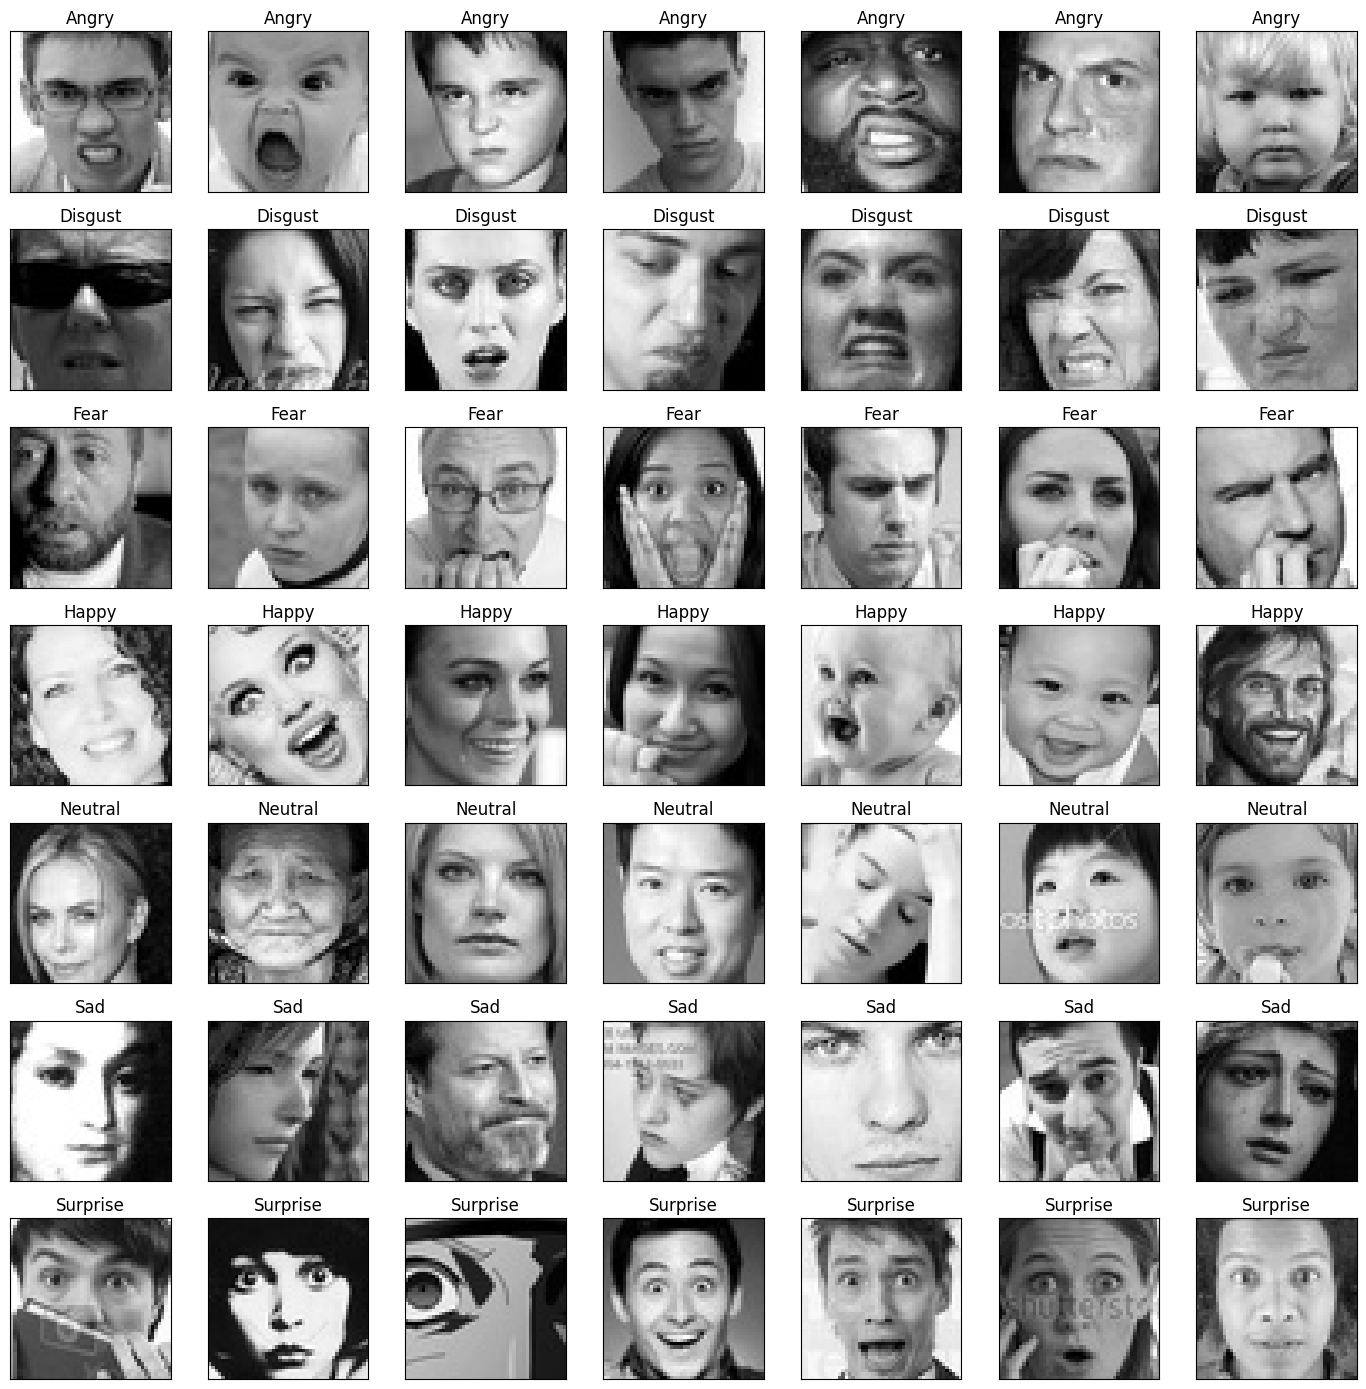

In [12]:
fig = plt.figure(figsize=(14, 14))
k = 0
for label in range(NUM_CLASSES):
    idxs = np.where(np.argmax(y_train, axis=1) == label)[0][:7]
    for idx in idxs:
        k += 1
        ax = plt.subplot(7, 7, k)
        ax.imshow(X_train[idx].reshape(48, 48), cmap='gray')
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(EMOTION_LABELS[label])
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'sample_images.png'))
plt.show()

# **Define CNN Model**

In [13]:
def create_cnn_model(input_shape=(48, 48, 1)):
    visible = Input(shape=input_shape, name='input')

    # Block 1
    x = Conv2D(64, 3, activation='relu', padding='same', name='conv1_1')(visible)
    x = BatchNormalization()(x)
    x = Conv2D(64, 3, activation='relu', padding='same', name='conv1_2')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, name='pool1_1')(x)
    x = Dropout(0.3, name='drop1_1')(x)

    # Block 2
    x = Conv2D(128, 3, activation='relu', padding='same', name='conv2_1')(x)
    x = BatchNormalization()(x)
    x = Conv2D(128, 3, activation='relu', padding='same', name='conv2_2')(x)
    x = BatchNormalization()(x)
    x = Conv2D(128, 3, activation='relu', padding='same', name='conv2_3')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, name='pool2_1')(x)
    x = Dropout(0.3, name='drop2_1')(x)

    # Block 3
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv3_1')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv3_2')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv3_3')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv3_4')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, name='pool3_1')(x)
    x = Dropout(0.3, name='drop3_1')(x)

    # Block 4
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv4_1')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv4_2')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv4_3')(x)
    x = BatchNormalization()(x)
    x = Conv2D(256, 3, activation='relu', padding='same', name='conv4_4')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, name='pool4_1')(x)
    x = Dropout(0.3, name='drop4_1')(x)

    # Block 5
    x = Conv2D(512, 3, activation='relu', padding='same', name='conv5_1')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, 3, activation='relu', padding='same', name='conv5_2')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, 3, activation='relu', padding='same', name='conv5_3')(x)
    x = BatchNormalization()(x)
    x = Conv2D(512, 3, activation='relu', padding='same', name='conv5_4')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, name='pool5_1')(x)
    x = Dropout(0.3, name='drop5_1')(x)

    x = Flatten(name='flatten')(x)
    output = Dense(NUM_CLASSES, activation='softmax', name='output')(x)

    return Model(inputs=visible, outputs=output)

print("CNN function ready")

CNN function ready


# **Compile CNN Model**

In [14]:
CNN_MODEL_PATH = os.path.join(MODELS_DIR, 'cnn_model.keras')

cnn_model = create_cnn_model()
opt = Adam(learning_rate=0.0001, decay=1e-6)
cnn_model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1_1 (MaxPooling2D)          │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1_1 (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_3 (Conv2D)                │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2_1 (MaxPooling2D)          │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2_1 (Dropout)               │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_3 (Conv2D)                │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 13,113,927 (50.03 MB)

 Trainable params: 13,104,711 (49.99 MB)

 Non-trainable params: 9,216 (36.00 KB)

# **Train CNN Model**

In [15]:

import os

CNN_MODEL_PATH = "/content/cnn_model.keras"
os.makedirs("/content", exist_ok=True)


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ✅ FIXED: input_shape changed from (48,48,3) to (48,48,1)
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(48, 48, 1)),
    BatchNormalization(),
    Conv2D(32, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(7, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,322,855 (5.05 MB)

 Trainable params: 1,321,703 (5.04 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [17]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
callbacks = [
    EarlyStopping(monitor='val_accuracy', min_delta=0.00005, patience=11,
                  verbose=1, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=7,
                      min_lr=1e-7, verbose=1),
    ModelCheckpoint(CNN_MODEL_PATH, monitor='val_accuracy',
                    save_best_only=True, verbose=1)
]

history_cnn = cnn_model.fit(
    train_flow,
    epochs=50,
    verbose=1,
    validation_data=test_flow,
    callbacks=callbacks
)

cnn_model.save(CNN_MODEL_PATH)
print(f"\n✅ CNN saved: {CNN_MODEL_PATH}")

Epoch 1/50
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.2189 - loss: 2.3769
Epoch 1: val_accuracy improved from None to 0.03859, saving model to /content/cnn_model.keras

Epoch 1: finished saving model to /content/cnn_model.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 52s 75ms/step - accuracy: 0.2527 - loss: 2.0856 - val_accuracy: 0.0386 - val_loss: 9.8413 - learning_rate: 0.0010
Epoch 2/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3253 - loss: 1.7360
Epoch 2: val_accuracy improved from 0.03859 to 0.40345, saving model to /content/cnn_model.keras

Epoch 2: finished saving model to /content/cnn_model.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.3519 - loss: 1.6658 - val_accuracy: 0.4035 - val_loss: 1.5633 - learning_rate: 0.0010
Epoch 3/50
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4094 - loss: 1.5227
Epoch 3: val_accuracy improved from 0.40345 to 0.43508, saving model to /content/cnn_model.keras

Epoch 3: finished saving model to /content/c

# **Training Plots**

In [18]:
# Accuracy
acc_df = pd.DataFrame({
    'epochs': range(len(history_cnn.history['accuracy'])),
    'accuracy': history_cnn.history['accuracy'],
    'val_accuracy': history_cnn.history['val_accuracy']
})
fig = px.line(acc_df, x='epochs', y=['accuracy', 'val_accuracy'],
              title='CNN — Training & Validation Accuracy')
fig.write_html(os.path.join(PLOTS_DIR, 'cnn_accuracy.html'))
fig.show()

# Loss
loss_df = pd.DataFrame({
    'epochs': range(len(history_cnn.history['loss'])),
    'loss': history_cnn.history['loss'],
    'val_loss': history_cnn.history['val_loss']
})
fig = px.line(loss_df, x='epochs', y=['loss', 'val_loss'],
              title='CNN — Training & Validation Loss')
fig.write_html(os.path.join(PLOTS_DIR, 'cnn_loss.html'))
fig.show()

# **Confusion Matrix & Metrics**

225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step


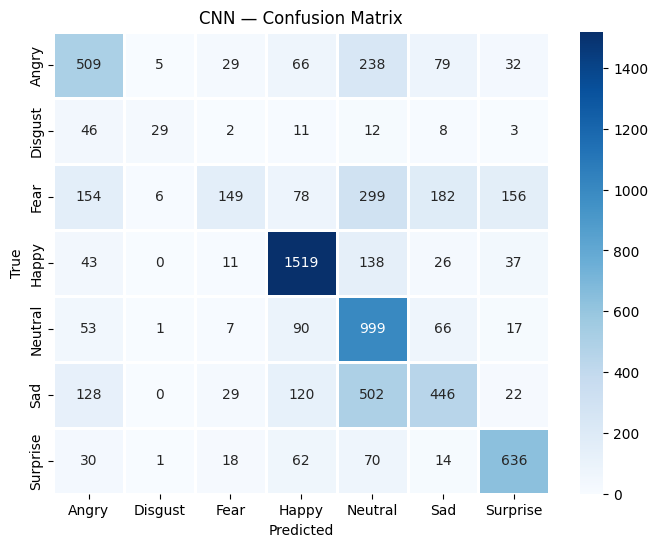


 Classification Report:
              precision    recall  f1-score   support

       Angry       0.53      0.53      0.53       958
     Disgust       0.69      0.26      0.38       111
        Fear       0.61      0.15      0.23      1024
       Happy       0.78      0.86      0.82      1774
     Neutral       0.44      0.81      0.57      1233
         Sad       0.54      0.36      0.43      1247
    Surprise       0.70      0.77      0.73       831

    accuracy                           0.60      7178
   macro avg       0.61      0.53      0.53      7178
weighted avg       0.61      0.60      0.57      7178



In [19]:
y_pred = cnn_model.predict(X_test, verbose=1)
y_pred_labels = np.argmax(y_pred, axis=1)
y_true_labels = np.argmax(y_test, axis=1)

classes = [EMOTION_LABELS[i] for i in range(NUM_CLASSES)]
cm = confusion_matrix(y_true_labels, y_pred_labels)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes,
            linewidths=1, annot=True, ax=ax, fmt='g', cmap='Blues')
plt.title('CNN — Confusion Matrix')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.savefig(os.path.join(PLOTS_DIR, 'cnn_confusion_matrix.png'))
plt.show()

print("\n Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=classes))

# **Upload music.csv**

In [20]:
from google.colab import files

print("Upload music.csv:")
uploaded_music = files.upload()

# Get uploaded filename
music_file = list(uploaded_music.keys())[0]
MUSIC_CSV = f"/content/{music_file}"
print(f"Music CSV: {MUSIC_CSV}")

Upload music.csv:


Saving music.csv to music.csv
Music CSV: /content/music.csv


# **Load Music Data & Recommend Function**

In [21]:
from google.colab import files
import pandas as pd
import numpy as np

# ---------- 1. Upload ----------
print("Upload music.csv:")
uploaded_music = files.upload()
music_file = list(uploaded_music.keys())[0]
MUSIC_CSV = f"/content/{music_file}"
print(f"Music CSV: {MUSIC_CSV}")

# ---------- 2. Load ----------
music_df = pd.read_csv(MUSIC_CSV)
music_df.columns = [c.strip().lower() for c in music_df.columns]
print(f"Music loaded: {music_df.shape}")
print("Columns:", music_df.columns.tolist())

# ---------- 3. Create 'mood' column from valence + energy ----------
def label_mood(row):
    v, e = row['valence'], row['energy']
    if v >= 0.5 and e >= 0.5:
        return 'Happy'
    elif v >= 0.5 and e < 0.5:
        return 'Calm'
    elif v < 0.5 and e >= 0.5:
        return 'Angry'
    else:
        return 'Sad'

if 'mood' not in music_df.columns:
    music_df['mood'] = music_df.apply(label_mood, axis=1)

print("\n Mood distribution:")
print(music_df['mood'].value_counts())

# ---------- 4. FIXED emotion → mood mapping ----------
EMOTION_TO_MOOD = {
    'Angry':    'Angry',    # angry face  → angry / intense music
    'Disgust':  'Angry',    # disgust     → intense music
    'Fear':     'Sad',      # fear        → dark / sad music
    'Happy':    'Happy',    # happy face  → happy music
    'Neutral':  'Calm',     # neutral     → calm music
    'Sad':      'Sad',      # sad face    → sad music  ✅ (was 'Happy' before)
    'Surprise': 'Happy',    # surprise    → upbeat music
}

# ---------- 5. Recommend ----------
def recommend_songs(emotion, top_k=5):
    mood = EMOTION_TO_MOOD.get(emotion)
    if mood is None:
        return pd.DataFrame()

    subset = music_df[music_df['mood'] == mood]

    # fallback if this mood has no songs
    if subset.empty:
        print(f"No songs for mood '{mood}' — showing top popular overall.")
        subset = music_df

    cols = [c for c in ['artist_name', 'track_name', 'popularity',
                        'valence', 'energy', 'mood'] if c in subset.columns]
    return subset.sort_values('popularity', ascending=False).head(top_k)[cols].reset_index(drop=True)

# ---------- 6. Test ----------
for emo in ['Sad', 'Happy', 'Angry', 'Neutral']:
    print(f"\n {emo} → mood '{EMOTION_TO_MOOD[emo]}':")
    print(recommend_songs(emo, top_k=5))

Upload music.csv:


Saving music.csv to music (1).csv
Music CSV: /content/music (1).csv
Music loaded: (50, 18)
Columns: ['id', 'artist_name', 'track_name', 'track_id', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']

 Mood distribution:
mood
Happy    24
Angry    17
Sad       7
Calm      2
Name: count, dtype: int64

 Sad → mood 'Sad':
      artist_name          track_name  popularity  valence  energy mood
0  Olivia Rodrigo     drivers license          92   0.1370   0.431  Sad
1  Olivia Rodrigo             traitor          92   0.0849   0.339  Sad
2   Lewis Capaldi   Someone You Loved          88   0.4460   0.405  Sad
3      Tate McRae  you broke me first          88   0.0823   0.373  Sad
4        Doja Cat             Streets          87   0.1890   0.463  Sad

 Happy → mood 'Happy':
      artist_name  track_name  popularity  valence  energy   mood
0  Olivia Rodrigo    good 4

# **Upload Face Image & Predict**

Upload a face image:


Saving images.jpg to images.jpg

  File: images.jpg


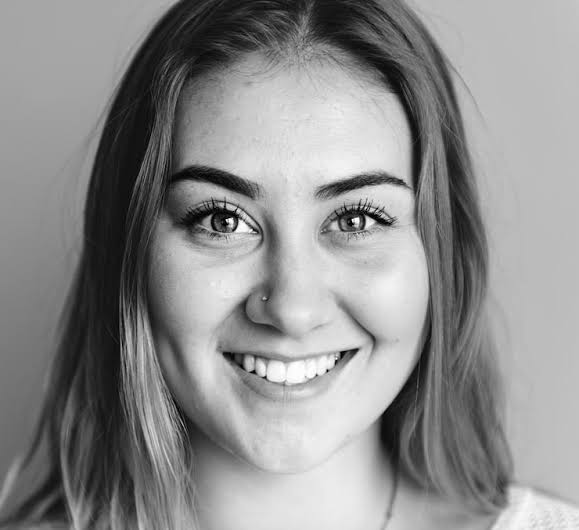


Detected Emotion: Fear (100.00%)

All probabilities:
  Angry     : 0.00%
  Disgust   : 0.00%
  Fear      : 100.00%
  Happy     : 0.00%
  Neutral   : 0.00%
  Sad       : 0.00%
  Surprise  : 0.00%

 Top 5 songs for mood 'Fear':



,artist_name,track_name,popularity,valence,energy,mood
0,Olivia Rodrigo,drivers license,92,0.1370,0.431,Sad
1,Olivia Rodrigo,traitor,92,0.0849,0.339,Sad
2,Lewis Capaldi,Someone You Loved,88,0.4460,0.405,Sad
3,Tate McRae,you broke me first,88,0.0823,0.373,Sad
4,Doja Cat,Streets,87,0.1890,0.463,Sad


In [22]:
from google.colab import files
from IPython.display import Image as IPImage, display

def predict_emotion_from_image(model, image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Cannot read: {image_path}")
    img = cv2.resize(img, (IMG_SHAPE, IMG_SHAPE))
    img = img.astype('float32') / 255.0
    img = img.reshape(1, IMG_SHAPE, IMG_SHAPE, 1)

    preds = model.predict(img, verbose=0)[0]
    idx = int(np.argmax(preds))
    return EMOTION_LABELS[idx], float(preds[idx]), preds

print("Upload a face image:")
uploaded_img = files.upload()

for filename in uploaded_img.keys():
    img_path = f"/content/{filename}"
    print(f"\n  File: {filename}")
    display(IPImage(img_path, width=300))

    emotion, confidence, all_probs = predict_emotion_from_image(cnn_model, img_path)
    print(f"\nDetected Emotion: {emotion} ({confidence:.2%})")

    print("\nAll probabilities:")
    for i, prob in enumerate(all_probs):
        print(f"  {EMOTION_LABELS[i]:10s}: {prob:.2%}")

    songs = recommend_songs(emotion, top_k=5)
    if not songs.empty:
        print(f"\n Top 5 songs for mood '{emotion}':\n")
        display(songs)
    else:
        print("  No songs for this mood.")

# **Download Trained Model**

In [23]:
from google.colab import files

# Download CNN model
files.download(CNN_MODEL_PATH)
print("✅ CNN model downloaded")

# Download plots
for f in os.listdir(PLOTS_DIR):
    files.download(os.path.join(PLOTS_DIR, f))
    print(f"✅ {f} downloaded")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ CNN model downloaded


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

✅ sample_images.png downloaded


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ cnn_accuracy.html downloaded
